In [1]:
from pathlib import Path
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
import spacy
import re
from difflib import unified_diff
import nltk
from nltk.corpus import stopwords
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
from hdbscan import HDBSCAN
from time import perf_counter

/home/oriana/.pyenv/versions/3.12.14/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1793408369.017340  114721 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793408370.593364  114721 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:

url = (
    "https://huggingface.co/datasets/reciTAL/mlsum/resolve/"
    "a018d1827f8bd5c4369ee7c5a54845c91c89ac28/"
    "es/mlsum-test.parquet"
)

ruta = Path("mlsum_es_test.parquet")

if not ruta.exists():
    respuesta = requests.get(url, timeout=180)
    respuesta.raise_for_status()
    ruta.write_bytes(respuesta.content)

df_original = pd.read_parquet(ruta)

print("Artículos descargados:", len(df_original))
print("Columnas:", df_original.columns.tolist())

display(df_original[["title", "date", "text"]].head(3))

Artículos descargados: 13920
Columnas: ['text', 'summary', 'topic', 'url', 'title', 'date']


,title,date,text
0,Un año de la carambola que lo cambió todo,01/06/2019,"Despedida de Rajoy, tras perder la votación de..."
1,Día de las Fuerzas Armadas: Sevilla homenajea ...,01/06/2019,Si no puede ver la retransmisión del desfile e...
2,"‘Ceebu jën’, el plato de los cuatro continentes",01/06/2019,Cocina como si danzara. Da pasos grandes y más...


In [17]:
from langdetect import DetectorFactory, detect_langs
from langdetect.lang_detect_exception import LangDetectException

SEMILLA = 42
DetectorFactory.seed = SEMILLA

MIN_PALABRAS = 5
UMBRAL_ES = 0.90


def detectar_idioma(texto):
    """Devuelve el idioma dominante y la puntuación asignada al español."""
    try:
        resultados = detect_langs(texto)

        idioma = resultados[0].lang
        puntuacion_es = next(
            (resultado.prob for resultado in resultados
             if resultado.lang == "es"),
            0.0
        )

        return idioma, float(puntuacion_es)

    except LangDetectException:
        return "indeterminado", 0.0


df = df_original.copy()

df["documento_id"] = [
    f"MLSUM_ES_TEST_{i:05d}"
    for i in range(len(df))
]

df["texto_limpio"] = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df["n_palabras"] = df["texto_limpio"].str.split().str.len()

n_original = len(df)

df = df.loc[df["n_palabras"] >= MIN_PALABRAS].copy()
n_articulos_cortos = n_original - len(df)

df["clave_duplicado"] = df["texto_limpio"].str.casefold()

n_antes = len(df)
df = (
    df.drop_duplicates("clave_duplicado")
    .drop(columns="clave_duplicado")
    .copy()
)
n_articulos_duplicados = n_antes - len(df)

if len(df) < 1000:
    raise ValueError("No hay suficientes artículos para la muestra inicial.")

muestra_inicial = df.sample(
    n=1000,
    random_state=SEMILLA
).reset_index(drop=True)

detecciones = pd.DataFrame(
    muestra_inicial["texto_limpio"].map(detectar_idioma).tolist(),
    columns=["idioma_detectado", "puntuacion_es"],
    index=muestra_inicial.index
)

muestra_inicial = muestra_inicial.join(detecciones)

es_espanol = (
    muestra_inicial["idioma_detectado"].eq("es")
    & muestra_inicial["puntuacion_es"].ge(UMBRAL_ES)
)

articulos_excluidos_idioma = (
    muestra_inicial.loc[~es_espanol].copy()
)

muestra = (
    muestra_inicial.loc[es_espanol]
    .copy()
    .reset_index(drop=True)
)

if muestra.empty:
    raise ValueError("No quedaron artículos tras el filtro de idioma.")

resumen_corpus = pd.Series({
    "Artículos originales": n_original,
    "Vacíos o cortos eliminados": n_articulos_cortos,
    "Duplicados exactos eliminados": n_articulos_duplicados,
    "Artículos en la muestra inicial": len(muestra_inicial),
    "Excluidos por idioma o puntuación insuficiente":
        len(articulos_excluidos_idioma),
    "Artículos conservados para segmentar": len(muestra)
})

display(resumen_corpus.to_frame("Cantidad"))

print("\nClasificación de idioma de la muestra inicial:")
display(
    muestra_inicial["idioma_detectado"]
    .value_counts()
    .rename_axis("Idioma")
    .to_frame("Artículos")
)

print("\nArtículos excluidos: revisar posibles errores del detector.")
display(
    articulos_excluidos_idioma[
        ["documento_id", "title", "idioma_detectado", "puntuacion_es"]
    ].head(20)
)

,Cantidad
Artículos originales,13920
Vacíos o cortos eliminados,0
Duplicados exactos eliminados,241
Artículos en la muestra inicial,1000
Excluidos por idioma o puntuación insuficiente,23
Artículos conservados para segmentar,977



Clasificación de idioma de la muestra inicial:


,Artículos
Idioma,
es,977
en,23



Artículos excluidos: revisar posibles errores del detector.


,documento_id,title,idioma_detectado,puntuacion_es
43,MLSUM_ES_TEST_12659,A quest for chocolate and cheese sparks a mini...,en,0.0
91,MLSUM_ES_TEST_08378,Madrid Central considered one of the most effe...,en,0.0
104,MLSUM_ES_TEST_03428,Spain will propose economy minister as new IMF...,en,0.0
261,MLSUM_ES_TEST_01130,"In Spain, parties argue over the meaning of “c...",en,0.0
267,MLSUM_ES_TEST_04543,"Spain’s rail company cancels 1,152 train servi...",en,0.0
286,MLSUM_ES_TEST_06626,Tests reveal listeria in three products from S...,en,0.0
288,MLSUM_ES_TEST_05428,Three French tourists placed in custody for ga...,en,0.0
329,MLSUM_ES_TEST_11372,Misinformation: The war on truth,en,0.0
334,MLSUM_ES_TEST_01031,Spanish producers call for bigger tax breaks f...,en,0.0
354,MLSUM_ES_TEST_13251,Thousands of police officers deployed in Catal...,en,0.0


,Palabras por artículo
count,977.000000
mean,782.879222
std,511.016555
min,53.000000
25%,480.000000
50%,714.000000
75%,960.000000
max,6510.000000


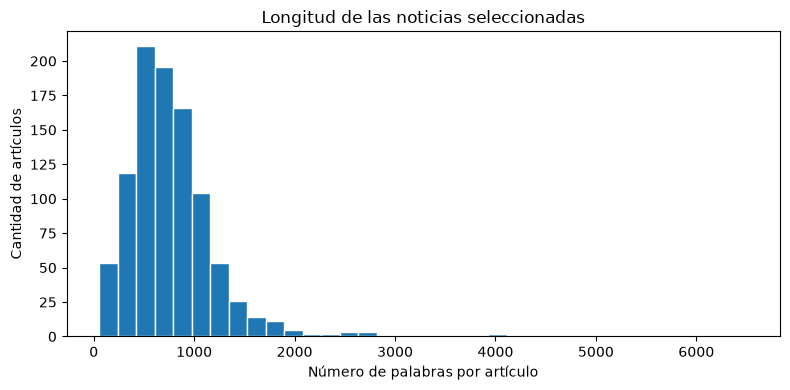

In [18]:

display(
    muestra["n_palabras"]
    .describe()
    .rename("Palabras por artículo")
    .to_frame()
)

plt.figure(figsize=(8, 4))
plt.hist(muestra["n_palabras"], bins=35, edgecolor="white")
plt.xlabel("Número de palabras por artículo")
plt.ylabel("Cantidad de artículos")
plt.title("Longitud de las noticias seleccionadas")
plt.tight_layout()
plt.show()

Medimos los tokens sobre la variable muestra que se creó.

In [19]:

NOMBRE_MODELO = (
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

modelo_embeddings = SentenceTransformer(NOMBRE_MODELO)
tokenizador = modelo_embeddings.tokenizer
limite_tokens = modelo_embeddings.max_seq_length

# Contamos la longitud completa
def contar_tokens(texto):
    return len(
        tokenizador(
            texto,
            add_special_tokens=True,
            truncation=False,
            verbose=False
        )["input_ids"]
    )

muestra["n_tokens"] = muestra["texto_limpio"].apply(contar_tokens)

resumen_tokens = pd.Series({
    "Artículos": len(muestra),
    "Límite del modelo": limite_tokens,
    "Tokens promedio": muestra["n_tokens"].mean(),
    "Mediana de tokens": muestra["n_tokens"].median(),
    "Máximo de tokens": muestra["n_tokens"].max(),
    "Artículos que exceden el límite":
        (muestra["n_tokens"] > limite_tokens).sum(),
    "Porcentaje que excede el límite":
        100 * (muestra["n_tokens"] > limite_tokens).mean()
})

display(resumen_tokens.to_frame("Resultado").round(2))

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2459.02it/s]


,Resultado
Artículos,977.00
Límite del modelo,128.00
Tokens promedio,1110.00
Mediana de tokens,1001.00
Máximo de tokens,9613.00
Artículos que exceden el límite,969.00
Porcentaje que excede el límite,99.18


In [20]:
nlp = spacy.blank("es")
nlp.add_pipe("sentencizer")


def dividir_oracion_larga(oracion):
    """Divide entre palabras solo cuando la oración supera el límite."""
    partes = []
    actual = ""

    for palabra in oracion.split():
        candidato = f"{actual} {palabra}".strip()

        if contar_tokens(candidato) <= limite_tokens:
            actual = candidato
        else:
            if actual:
                partes.append(actual)

            # Detectar caso excepcional sin truncarlo.
            if contar_tokens(palabra) > limite_tokens:
                raise ValueError(
                    f"Una palabra supera el límite; revisar: {palabra[:80]}"
                )

            actual = palabra

    if actual:
        partes.append(actual)

    return partes


def segmentar_documento(doc):
    """Agrupa oraciones consecutivas, sin solapamiento."""
    bloques = []
    actual = ""
    oraciones_divididas = 0

    for sentencia in doc.sents:
        oracion = " ".join(sentencia.text.split())

        if not oracion:
            continue

        if contar_tokens(oracion) > limite_tokens:
            oraciones_divididas += 1
            unidades = dividir_oracion_larga(oracion)
        else:
            unidades = [oracion]

        for unidad in unidades:
            candidato = f"{actual} {unidad}".strip()

            if contar_tokens(candidato) <= limite_tokens:
                actual = candidato
            else:
                bloques.append(actual)
                actual = unidad

    if actual:
        bloques.append(actual)

    return bloques, oraciones_divididas

In [21]:
# Reiniciar los resultados para evitar registros de ejecuciones anteriores
registros = []
total_oraciones_divididas = 0
cambios_de_espaciado = []


def sin_espacios(texto):
    return re.sub(r"\s+", "", texto)


documentos = nlp.pipe(
    muestra["texto_limpio"].tolist(),
    batch_size=32
)

for fila, doc in zip(muestra.to_dict("records"), documentos):

    bloques, n_divididas = segmentar_documento(doc)
    total_oraciones_divididas += n_divididas
    
    # Comprobar que se conserva el contenido
    reconstruido = " ".join(bloques)
    original = fila["texto_limpio"]

    if reconstruido != original:
        if sin_espacios(reconstruido) == sin_espacios(original):
            cambios_de_espaciado.append(fila["documento_id"])
        else:
            diferencia = "\n".join(
                unified_diff(
                    original.split(),
                    reconstruido.split(),
                    fromfile="original",
                    tofile="reconstruido",
                    lineterm=""
                )
            )

            raise ValueError(
                f"Cambió el contenido en {fila['documento_id']}:\n"
                f"{diferencia[:2000]}"
            )

    # Registrar los segmentos y conservar su artículo de origen.
    for numero, texto in enumerate(bloques, start=1):
        registros.append({
            "documento_id": fila["documento_id"],
            "segmento_id": (
                f"{fila['documento_id']}_S{numero:03d}"
            ),
            "title": fila.get("title", ""),
            "date": fila.get("date", ""),
            "url": fila.get("url", ""),
            "texto": texto,
            "n_palabras": len(texto.split()),
            "n_tokens": contar_tokens(texto)
        })

segmentos_brutos = pd.DataFrame(registros)

# Validaciones finales.
assert not segmentos_brutos.empty, "No se generaron segmentos."

assert segmentos_brutos["n_tokens"].max() <= limite_tokens, (
    "Hay segmentos que exceden el límite de tokens."
)

assert segmentos_brutos["segmento_id"].is_unique, (
    "Hay identificadores de segmento repetidos."
)

print("Artículos procesados:", len(muestra))
print("Segmentos generados:", len(segmentos_brutos))
print("Oraciones que requirieron división:", total_oraciones_divididas)
print(
    "Artículos con cambios únicamente de espaciado:",
    len(cambios_de_espaciado)
)
print(
    "Máximo de tokens por segmento:",
    segmentos_brutos["n_tokens"].max()
)

display(segmentos_brutos.head())

Artículos procesados: 977
Segmentos generados: 10746
Oraciones que requirieron división: 111
Artículos con cambios únicamente de espaciado: 687
Máximo de tokens por segmento: 128


,documento_id,segmento_id,title,date,url,texto,n_palabras,n_tokens
0,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S001,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,El pleno del Parlamento de Cataluña ha burlado...,54,66
1,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S002,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,La reunión debía iniciarse a las tres de la ta...,81,110
2,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S003,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,El PSC y el PP no han participado en la votaci...,54,71
3,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S004,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,Con el adelanto inesperado del pleno acordado ...,60,86
4,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S005,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,Esa suspensión impidió el debate de la moción ...,45,58


In [ ]:
segmentos = segmentos_brutos.copy()
n_segmentos_inicial = len(segmentos)

# liminar segmentos vacíos o muy cortos
segmentos = segmentos.loc[
    segmentos["n_palabras"] >= MIN_PALABRAS
].copy()

n_segmentos_cortos = n_segmentos_inicial - len(segmentos)

#  Eliminar duplicados con espacos y mayúsculas
segmentos["clave_duplicado"] = (
    segmentos["texto"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.casefold()
)

n_antes = len(segmentos)

segmentos = (
    segmentos.drop_duplicates("clave_duplicado")
    .drop(columns="clave_duplicado")
    .reset_index(drop=True)
)

n_segmentos_duplicados = n_antes - len(segmentos)

# Idiooma de cada segmento
detecciones_segmentos = pd.DataFrame(
    segmentos["texto"].map(detectar_idioma).tolist(),
    columns=["idioma_detectado", "puntuacion_es"],
    index=segmentos.index
)

segmentos = segmentos.join(detecciones_segmentos)

es_espanol = (
    segmentos["idioma_detectado"].eq("es")
    & segmentos["puntuacion_es"].ge(UMBRAL_ES)
)

segmentos_excluidos_idioma = segmentos.loc[~es_espanol].copy()

segmentos = (
    segmentos.loc[es_espanol]
    .copy()
    .reset_index(drop=True)
)

assert len(segmentos) >= 500, "Quedaron menos de 500 segmentos."
assert segmentos["segmento_id"].is_unique
assert segmentos["n_tokens"].max() <= limite_tokens
assert segmentos["idioma_detectado"].eq("es").all()
assert segmentos["puntuacion_es"].ge(UMBRAL_ES).all()

resumen_segmentacion = pd.Series({
    "Artículos de la muestra inicial": len(muestra_inicial),
    "Artículos conservados antes de segmentar": len(muestra),
    "Segmentos generados": n_segmentos_inicial,
    "Segmentos cortos eliminados": n_segmentos_cortos,
    "Segmentos duplicados exactos eliminados": n_segmentos_duplicados,
    "Segmentos excluidos por idioma o puntuación":
        len(segmentos_excluidos_idioma),
    "Segmentos finales": len(segmentos),
    "Artículos con segmentos conservados":
        segmentos["documento_id"].nunique(),
    "Palabras promedio por segmento":
        segmentos["n_palabras"].mean(),
    "Tokens promedio por segmento":
        segmentos["n_tokens"].mean(),
    "Máximo de tokens por segmento":
        segmentos["n_tokens"].max(),
    "Segmentos que exceden el límite":
        (segmentos["n_tokens"] > limite_tokens).sum()
})

display(resumen_segmentacion.to_frame("Resultado").round(2))

print("\nSegmentos excluidos: muestra para revisión.")
with pd.option_context("display.max_colwidth", 180):
    display(
        segmentos_excluidos_idioma[
            ["segmento_id", "idioma_detectado", "puntuacion_es", "texto"]
        ].head(15)
    )

docs = segmentos["texto"].tolist()

,Resultado
Artículos de la muestra inicial,1000.00
Artículos conservados antes de segmentar,977.00
Segmentos generados,10746.00
Segmentos cortos eliminados,4.00
Segmentos duplicados exactos eliminados,40.00
Segmentos excluidos por idioma o puntuación,58.00
Segmentos finales,10644.00
Artículos con segmentos conservados,977.00
Palabras promedio por segmento,71.88
Tokens promedio por segmento,103.13



Segmentos excluidos: muestra para revisión.


,segmento_id,idioma_detectado,puntuacion_es,texto
46,MLSUM_ES_TEST_11157_S008,ca,0.167331,"Para tratar de facilitar el diálogo, la formación eliminó la palabra referéndum del documento con más de 300 medidas que le enviaron a Pedro Sánchez el pasado agosto para desen..."
161,MLSUM_ES_TEST_03589_S014,es,0.714282,"Paul Krugman es premio Nobel de Economía © The New York Times, 2019 Traducción de News Clips"
412,MLSUM_ES_TEST_07096_S007,es,0.571429,"Puedes seguir EL PAÍS Opinión en Facebook, Twitter o suscribirte aquí a la Newsletter."
443,MLSUM_ES_TEST_03481_S012,es,0.714283,"“Aprehéndeme, ahora que paso ante ti, si tienes fuerza para ello, y lucha por resolver el enigma de felicidad que te propongo... e inmediatamente la reconocí, era Venecia”. Víc..."
993,MLSUM_ES_TEST_00099_S009,ca,0.192243,"Puedes seguir Deportes de EL PAÍS en Facebook, Twitter o suscribirte aquí a la Newsletter."
1061,MLSUM_ES_TEST_02229_S026,en,0.262677,"O incluso menos. Puedes seguir ICON en Facebook, Twitter, Instagram,o suscribirte aquí a la Newsletter."
1533,MLSUM_ES_TEST_04379_S014,ca,0.428574,"De no ocurrir, vaticina: ""La gente se va a ir a sus casas, va a estar un ratito ahí y va a volver a la calle""."
1554,MLSUM_ES_TEST_13585_S004,es,0.714283,"Cuando dejé la presidencia, me entraron ganas de volver a mi [Estado de] Pernambuco, ganas de vivir cerca de la playa, pero en un sitio en el que pudiera ir a la playa. Pensaba..."
1976,MLSUM_ES_TEST_01638_S008,af,0.428570,"Ángel Berges, vicepresidente de Afi."
2199,MLSUM_ES_TEST_07632_S019,hu,0.000000,Behnam Yakhchali [Irán] falla el triple.


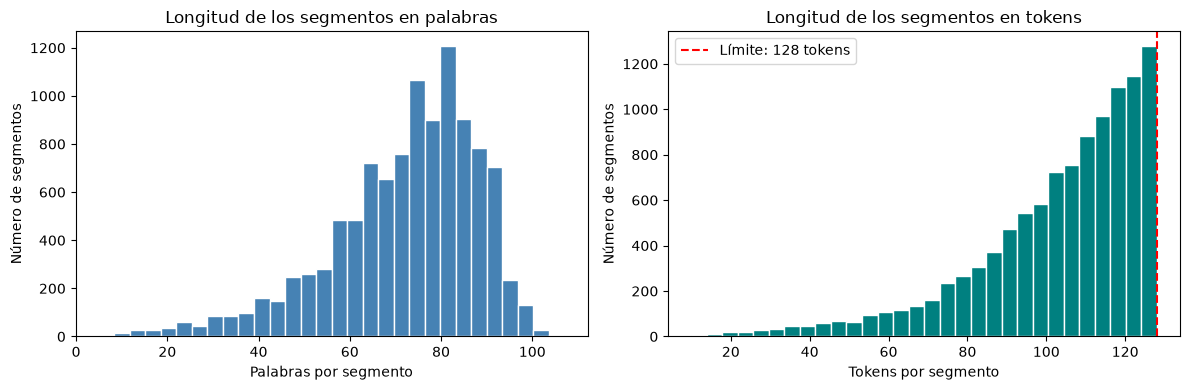

,n_palabras,n_tokens
count,10644.00,10644.00
mean,71.88,103.13
std,16.34,21.58
min,5.00,10.00
25%,63.00,92.00
50%,75.00,109.00
75%,84.00,120.00
max,107.00,128.00


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    segmentos["n_palabras"], bins=30,
    color="steelblue", edgecolor="white"
)
axes[0].set(
    title="Longitud de los segmentos en palabras",
    xlabel="Palabras por segmento",
    ylabel="Número de segmentos"
)

axes[1].hist(
    segmentos["n_tokens"], bins=30,
    color="teal", edgecolor="white"
)
axes[1].axvline(
    limite_tokens, color="red", linestyle="--",
    label=f"Límite: {limite_tokens} tokens"
)
axes[1].set(
    title="Longitud de los segmentos en tokens",
    xlabel="Tokens por segmento",
    ylabel="Número de segmentos"
)
axes[1].legend()

plt.tight_layout()
plt.show()

display(segmentos[["n_palabras", "n_tokens"]].describe().round(2))

In [25]:
ejemplos = segmentos.sample(n=5, random_state=42)

for fila in ejemplos.itertuples():
    print(f"\n{fila.segmento_id} | {fila.n_tokens} tokens")
    print(f"Título: {fila.title}")
    print(fila.texto)
    print("-" * 70)

docs = segmentos["texto"].tolist()


MLSUM_ES_TEST_12476_S002 | 97 tokens
Título: El mundo necesita el liderazgo de América Latina en la crisis climática
Si las tendencias actuales continúan, la deforestación podría duplicarse a 48 millones de hectáreas para 2030. En el caso de los países de América Latina, los incendios han puesto de relieve la responsabilidad crucial de nuestra región para con esta maravillosa región del planeta. Como presidente de mi país, era consciente de la responsabilidad de velar no solo por el pueblo de Colombia sino también por sus recursos naturales, ligados ambos de manera intrínseca.
----------------------------------------------------------------------

MLSUM_ES_TEST_06163_S004 | 101 tokens
Título: Franz Kafka: Los papeles de Kafka
Tal vez, si es que se puede calificar así una misiva rematada con un “tenemos que decirnos adiós”. Mejor publicitar a un escritor enamorado, pensarían los dueños del hotel, que a uno en fuga de su prometida. Kafka, que necesitaba una soledad extrema para crear, l

## Modelado


Se emplean los segmentos obtenidos de una muestra aleatoria de 1000
noticias del subconjunto español de MLSUM. Los resuenes y las categorías riginales del corpus no se utilizan para construir los tópicos. La segmentación se ajusta al límite de secuencia que informa el modelon son: 128 tokens en el entorno utilizado.


In [26]:
import sys
import random
import importlib.metadata as metadata
import torch
from IPython.display import display, Markdown
from bertopic.vectorizers import ClassTfidfTransformer
from sklearn.metrics.pairwise import cosine_similarity

SEMILLA = 42

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)

nltk.download("stopwords", quiet=True, raise_on_error=True)

# Se añaden stopwords en ingles porque algunas noticias lo contienne en su fragmento
stopwords_modelado = sorted(
    set(stopwords.words("spanish")))

docs = segmentos["texto"].tolist()

assert len(docs) >= 500
assert len(docs) == len(segmentos)
assert segmentos["segmento_id"].is_unique
assert segmentos["n_tokens"].max() <= limite_tokens
assert all(isinstance(texto, str) and texto.strip() for texto in docs)

paquetes = [
    "bertopic", "sentence-transformers", "transformers",
    "umap-learn", "hdbscan", "scikit-learn",
    "numpy", "pandas", "torch", "spacy", "nltk"
]

versiones = pd.DataFrame({
    "Paquete": paquetes,
    "Versión": [metadata.version(p) for p in paquetes]
})

print("Python:", sys.version.split()[0])
print("Semilla:", SEMILLA)
print("Modelo de embeddings:", NOMBRE_MODELO)
print("Dispositivo:", modelo_embeddings.device)
print("Límite de tokens:", limite_tokens)
print("Segmentos para modelar:", len(docs))
print("Stopwords utilizadas:", len(stopwords_modelado))

display(versiones)

Python: 3.12.14
Semilla: 42
Modelo de embeddings: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Dispositivo: cpu
Límite de tokens: 128
Segmentos para modelar: 10644
Stopwords utilizadas: 313


,Paquete,Versión
0,bertopic,0.17.4
1,sentence-transformers,6.2.0
2,transformers,5.22.0
3,umap-learn,0.5.12
4,hdbscan,0.8.44
5,scikit-learn,1.9.1
6,numpy,2.5.2
7,pandas,3.1.0
8,torch,2.15.0
9,spacy,3.8.18


## Embeddings

In [27]:
inicio = perf_counter()

embeddings = modelo_embeddings.encode(
    docs,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

tiempo_embeddings = perf_counter() - inicio

assert embeddings.shape[0] == len(docs)
assert np.isfinite(embeddings).all()

print("Dimensiones:", embeddings.shape)
print(f"Tiempo de embeddings: {tiempo_embeddings:.1f} segundos")

Batches: 100%|██████████| 333/333 [03:41<00:00,  1.50it/s]

Dimensiones: (10644, 384)
Tiempo de embeddings: 221.6 segundos


## Comparación de modelos

In [28]:
def crear_modelo(min_cluster_size):
    return BERTopic(
        embedding_model=modelo_embeddings,
        umap_model=UMAP(
            n_neighbors=15,
            n_components=5,
            min_dist=0.0,
            metric="cosine",
            random_state=SEMILLA,
            n_jobs=1
        ),
        hdbscan_model=HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=10,
            metric="euclidean",
            cluster_selection_method="leaf",
            prediction_data=True
        ),
        vectorizer_model=CountVectorizer(
            stop_words=stopwords_modelado,
            ngram_range=(1, 2),
            min_df=1
        ),
        ctfidf_model=ClassTfidfTransformer(
            reduce_frequent_words=True
        ),
        nr_topics=None,
        calculate_probabilities=False,
        verbose=True
    )


configuraciones = {"A": 30, "B": 60}

modelos = {}
asignaciones = {}
resultados = []

for nombre, tamano_minimo in configuraciones.items():
    modelo = crear_modelo(tamano_minimo)

    inicio = perf_counter()
    topicos, _ = modelo.fit_transform(docs, embeddings=embeddings)
    segundos = perf_counter() - inicio

    topicos = np.asarray(topicos, dtype=int)
    info = modelo.get_topic_info()
    validos = info.loc[info["Topic"] != -1]

    modelos[nombre] = modelo
    asignaciones[nombre] = topicos.copy()

    resultados.append({
        "Configuración": nombre,
        "min_cluster_size": tamano_minimo,
        "Tópicos": len(validos),
        "Outliers": int((topicos == -1).sum()),
        "% outliers": 100 * (topicos == -1).mean(),
        "Mediana de segmentos por tópico": (
            validos["Count"].median() if len(validos) else np.nan
        ),
        "Tópico mayor": (
            validos["Count"].max() if len(validos) else 0
        ),
        "Tiempo (s)": segundos
    })

comparacion = pd.DataFrame(resultados).set_index("Configuración")

display(comparacion.round(2))

2026-10-30 19:50:10,395 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-30 19:50:15,074 - BERTopic - Dimensionality - Completed ✓
2026-10-30 19:50:15,076 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-30 19:50:15,399 - BERTopic - Cluster - Completed ✓
2026-10-30 19:50:15,404 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-30 19:50:17,467 - BERTopic - Representation - Completed ✓
2026-10-30 19:50:18,104 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-30 19:50:22,746 - BERTopic - Dimensionality - Completed ✓
2026-10-30 19:50:22,747 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-30 19:50:23,040 - BERTopic - Cluster - Completed ✓
2026-10-30 19:50:23,043 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-30 19:50:25,147 - BERTopic - Representation - Completed ✓


,min_cluster_size,Tópicos,Outliers,% outliers,Mediana de segmentos por tópico,Tópico mayor,Tiempo (s)
Configuración,,,,,,,
A,30,69,5494,51.62,60.0,190,7.71
B,60,38,5137,48.26,136.0,404,7.59


## Diagnóstico de configuraciones

In [ ]:
def diagnosticar_topicos(nombre):
    datos = segmentos[
        ["documento_id", "segmento_id"]
    ].copy()

    datos["Topic"] = asignaciones[nombre]

    resumen = (
        datos.groupby("Topic")
        .agg(
            segmentos=("segmento_id", "size"),
            articulos_distintos=("documento_id", "nunique")
        )
    )

    aportes = datos.groupby(["Topic", "documento_id"]).size()

    resumen["max_segmentos_de_un_articulo"] = (
        aportes.groupby(level="Topic").max()
    )

    resumen["aporte_dominante_pct"] = (
        100
        * resumen["max_segmentos_de_un_articulo"]
        / resumen["segmentos"]
    )

    info = modelos[nombre].get_topic_info()[
        ["Topic", "Name", "Representation"]
    ]

    diagnostico = info.merge(
        resumen.reset_index(),
        on="Topic",
        validate="one_to_one"
    )

    # Señal exploratoria 
    diagnostico["revisar_concentracion"] = (
        (diagnostico["Topic"] != -1)
        & (diagnostico["aporte_dominante_pct"] >= 40)
    )

    return diagnostico.sort_values(
        "segmentos", ascending=False
    ).reset_index(drop=True)


diagnosticos = {
    nombre: diagnosticar_topicos(nombre)
    for nombre in configuraciones
}

for nombre, tabla in diagnosticos.items():
    print(f"\nConfiguración {nombre}")

    with pd.option_context(
        "display.max_rows", None,
        "display.max_colwidth", 110
    ):
        display(
            tabla[[
                "Topic", "Representation",
                "segmentos", "articulos_distintos",
                "aporte_dominante_pct",
                "revisar_concentracion"
            ]].round(2)
        )


Configuración A


,Topic,Representation,segmentos,articulos_distintos,aporte_dominante_pct,revisar_concentracion
0,-1,"[años, si, millones, ser, solo, vida, madrid, hace, año, después]",5494,883,0.66,False
1,0,"[habitaciones, hotel, suites, villa, edificio, plaza, parador, canalejas, venecia, four]",190,58,16.32,False
2,1,"[sánchez, psoe, rivera, pedro sánchez, podemos, iglesias, pedro, ciudadanos, investidura, pp]",180,69,5.00,False
3,2,"[votos, escaños, partidos, elecciones, partido, pp, encuestas, syriza, podemos, democracia]",170,90,8.82,False
4,3,"[barça, messi, jugadores, equipo, griezmann, fútbol, club, selección, goles, puntos]",169,37,7.10,False
5,4,"[brexit, johnson, 10 2019, 19 10, 19, parlamento, ue, acuerdo, boris, 10]",169,29,33.14,False
6,5,"[células, vih, tratamiento, enfermedad, cáncer, brote, listeria, vacuna, pacientes, carne mechada]",163,42,11.66,False
7,6,"[guatemala, migrantes, méxico, frontera, autobús, unidos, trump, coyote, país seguro, maleta]",159,30,44.65,True
8,7,"[educación, alumnos, examen, profesores, matemáticas, dislexia, colegios, niños, educativa, escuelas]",150,47,10.00,False
9,8,"[cine, película, comedia, personajes, serie, personaje, intérpretes, actriz, sitcom, reparto]",145,62,8.28,False



Configuración B


,Topic,Representation,segmentos,articulos_distintos,aporte_dominante_pct,revisar_concentracion
0,-1,"[años, si, gobierno, españa, ser, madrid, solo, dos, vida, hace]",5137,866,0.70,False
1,0,"[equipo, fútbol, barça, min, entrenador, jugadores, messi, carapaz, final, seguir deportes]",404,74,4.21,False
2,1,"[madre, pareja, hijos, hija, matrimonio, casa, familia, padre, clooney, esposa]",309,103,4.53,False
3,2,"[sánchez, psoe, podemos, pedro sánchez, rivera, pedro, iglesias, pp, ciudadanos, líder]",303,104,3.63,False
4,3,"[datos, usuario, información, cuentas, redes, filosofía, calvo guirado, guirado, ciencia, pantallas]",287,84,8.36,False
5,4,"[agua, climático, cambio climático, climática, mar menor, peces, nitratos, cambio, zonas, ríos]",265,65,9.43,False
6,5,"[canción, canciones, rock, the, swift, disco, música, pop, cantante, camilo]",232,40,22.41,False
7,6,"[carne, células, productos, tratamiento, vih, cáncer, enfermedad, vacuna, brote, alimentos]",227,59,8.37,False
8,7,"[mujeres, violencia, mujer, lideresas, padres, violencia género, machista, género, feminista, violación]",196,75,8.67,False
9,8,"[habitaciones, hotel, suites, villa, edificio, plaza, parador, canalejas, venecia, four]",190,58,16.32,False


## Segmentos representativos por tópico

In [30]:
CONFIG_FINAL = "B"

modelo_final = modelos[CONFIG_FINAL]
topicos_finales = asignaciones[CONFIG_FINAL].copy()

segmentos_resultados = segmentos.copy()

for nombre, topicos in asignaciones.items():
    segmentos_resultados[f"topico_{nombre}"] = topicos

segmentos_resultados["Topic"] = topicos_finales

ids_topicos = sorted(
    int(t)
    for t in modelo_final.get_topic_info()["Topic"]
    if t != -1
)

if not ids_topicos:
    raise ValueError("La configuración seleccionada no produjo tópicos.")

# Criterio exploratorio para evitar ejemplos léxicamente redundantes.
# No equivale a una detección exhaustiva de paráfrasis.
UMBRAL_JACCARD = 0.60

palabras_excluidas = set(stopwords_modelado)


def palabras_contenido(texto):
    return {
        palabra
        for palabra in re.findall(
            r"\b[^\W\d_]{3,}\b",
            texto.casefold()
        )
        if palabra not in palabras_excluidas
    }


def jaccard(conjunto_a, conjunto_b):
    union = conjunto_a | conjunto_b
    return (
        len(conjunto_a & conjunto_b) / len(union)
        if union else 0.0
    )


registros_ejemplos = []
registros_cobertura = []

for topico in ids_topicos:
    posiciones = np.flatnonzero(topicos_finales == topico)

    # Ordenar candidatos por proximidad al centroide semántico.
    vectores = embeddings[posiciones]
    centroide = vectores.mean(axis=0, keepdims=True)

    similitudes = cosine_similarity(
        vectores, centroide
    ).ravel()

    orden = np.argsort(-similitudes, kind="stable")

    articulos_usados = set()
    conjuntos_elegidos = []
    elegidos = []

    for indice_local in orden:
        posicion = posiciones[indice_local]
        fila = segmentos_resultados.iloc[posicion]

        # Como máximo, un ejemplo por artículo dentro de cada tópico.
        if fila["documento_id"] in articulos_usados:
            continue

        conjunto = palabras_contenido(fila["texto"])

        if not conjunto:
            continue

        # Evitar contenido muy parecido incluso entre artículos distintos.
        if any(
            jaccard(conjunto, anterior) >= UMBRAL_JACCARD
            for anterior in conjuntos_elegidos
        ):
            continue

        elegidos.append({
            "Topic": topico,
            "ejemplo": len(elegidos) + 1,
            "segmento_id": fila["segmento_id"],
            "documento_id": fila["documento_id"],
            "titulo": fila["title"],
            "url": fila["url"],
            "similitud_centroide": float(
                similitudes[indice_local]
            ),
            "texto": fila["texto"]
        })

        articulos_usados.add(fila["documento_id"])
        conjuntos_elegidos.append(conjunto)

        if len(elegidos) == 3:
            break

    registros_ejemplos.extend(elegidos)

    registros_cobertura.append({
        "Topic": topico,
        "articulos_disponibles": (
            segmentos_resultados.iloc[posiciones][
                "documento_id"
            ].nunique()
        ),
        "ejemplos_seleccionados": len(elegidos),
        "al_menos_dos_ejemplos": len(elegidos) >= 2
    })

    palabras = [
        palabra
        for palabra, peso in modelo_final.get_topic(topico)[:10]
    ]

    display(Markdown(
        f"### Tópico {topico}\n\n"
        f"**Palabras:** {', '.join(palabras)}"
    ))

    for ejemplo in elegidos:
        print(
            f"\nEjemplo {ejemplo['ejemplo']} | "
            f"{ejemplo['segmento_id']}"
        )
        print("Noticia:", ejemplo["titulo"])
        print(ejemplo["texto"])

    if len(elegidos) < 2:
        print(
            "\nREVISAR: no se encontraron dos ejemplos que "
            "cumplan simultáneamente los criterios de "
            "diversidad de artículo y baja redundancia léxica."
        )

ejemplos_topicos = pd.DataFrame(registros_ejemplos)
cobertura_ejemplos = pd.DataFrame(registros_cobertura)

display(cobertura_ejemplos)

# Comprobaciones de la selección.
if not ejemplos_topicos.empty:
    assert not ejemplos_topicos.duplicated(
        ["Topic", "documento_id"]
    ).any()

    assert not ejemplos_topicos.duplicated(
        ["Topic", "segmento_id"]
    ).any()

### Tópico 0

**Palabras:** equipo, fútbol, barça, min, entrenador, jugadores, messi, carapaz, final, seguir deportes


Ejemplo 1 | MLSUM_ES_TEST_06701_S019
Noticia: Teresa Portela, bronce mundial con 37 años, primera española que disputará seis Juegos Olímpicos
España es el único país que ha conseguido dos medallas en esa distancia. Bronce para Portela, y bronce también para Carlos Garrote. El zamorano de 28 años llegaba a Hungría para defender el título conseguido el año pasado en Portugal. Salió muy rápido, pero le adelantaron en los últimos metros el campeón olímpico en Río, Liam Heath y el serbio Strahinja Stefanovic. “¡ Íbamos a ganar, me cago en la leche! Por un pelo”, dijo nada más llegar a la zona mixta.

Ejemplo 2 | MLSUM_ES_TEST_12007_S004
Noticia: El Valencia viaja a Lille aferrado al timón de Parejo
Primero, fichar a Rafinha como acompañante de Dani Parejo, cuya condición de conductor irreemplazable del juego exponía al equipo al desplome en caso de baja. Segundo, fichar un goleador que pusiera remedio a la falta de pegada. Lo reflejaban las tablas. El Valencia fue el único de los 20 equip

### Tópico 1

**Palabras:** madre, pareja, hijos, hija, matrimonio, casa, familia, padre, clooney, esposa


Ejemplo 1 | MLSUM_ES_TEST_05959_S006
Noticia: 30 tiros sobre el pastor evangélico de los 55 hijos
Cuando conoció a su marido, ya era madre de 37 niños que sobrevivieron a una matanza en la estación Central de Brasil. Lógico que la recién estrenada parlamentaria diera su testimonio en la Cámara de Diputados el último Día Mundial de la Adopción. “ Los estaban matando por vivir en la calle”, relató. A medida que iban ampliando la familia, la fama se acrecentaba; tanto que inspiró una película y logró un disco de oro como cantante de góspel. Flordelis se convirtió en una exitosa marca.

Ejemplo 2 | MLSUM_ES_TEST_12347_S002
Noticia: Robert Gavin, el combativo abogado por el que Telma Ortiz ha abandonado su escogido anonimato
La cuñada de Felipe VI abandonó por unas horas su perfil bajo para gritarle al mundo que lo suyo con el exmarido de la violinista Sharon Corr va muy en serio. Algo que su reciente traslado a Madrid –donde su novio vive desde hace más de un año–, junto a su hija Amanda 

### Tópico 2

**Palabras:** sánchez, psoe, podemos, pedro sánchez, rivera, pedro, iglesias, pp, ciudadanos, líder

...

### Tópico 36

**Palabras:** prisión, cárcel, juez, detenido, federales, años prisión, agentes federales, agentes, moro, detención


Ejemplo 1 | MLSUM_ES_TEST_10740_S002
Noticia: Iberdrola dice que no encontró irregularidades tras auditar los pagos a Villarejo
La investigación se desencadenó a raíz de que el comisario jubilado entrara en la cárcel por liderar supuestamente una organización criminal que se dedicaba al espionaje, en lo que se llamó caso Tándem y que ahora ya cuenta con 18 piezas separadas. Villarejo tuvo contratos con Iberdrola entre 2004 y 2017, año en que el juez Manuel García-Castellón le envió a prisión. Precisamente, el juez acaba de ampliar dos años más la prisión provisional por el riesgo de fuga y destrucción de pruebas.

Ejemplo 2 | MLSUM_ES_TEST_10832_S007
Noticia: El escándalo de torturas que Bolsonaro considera una “tontería” y Moro, “un “malentendido”
La denuncia y la decisión de apartar a Rottava están en el ámbito de la Justicia Federal. Sin embargo, la Justicia del Estado de Pará también ha refutado las denuncias. La nota del departamento penitenciario dice que informes periciales de 

### Tópico 37

**Palabras:** emisiones, carbono, ozono, aviación, aviones, iag, contaminante, gases, walsh, vuelos


Ejemplo 1 | MLSUM_ES_TEST_01378_S002
Noticia: Los malos humos amenazan a la aviación
El movimiento coincide con varias iniciativas para limitar la huella contaminante de la aviación –que emite, por ejemplo, hasta 20 veces más de CO 2 por kilómetro y pasajero que el tren, según la Agencia Europea del Medio Ambiente–. Holanda lidera a los partidarios de crear nuevos impuestos, en Francia se ha iniciado un debate sobre si se deben prohibir los trayectos cortos para los que haya alternativa en tren y los principales candidatos a presidir la Comisión Europea son favorables a imponer tasas ecológicas a las compañías. “

Ejemplo 2 | MLSUM_ES_TEST_10806_S010
Noticia: IAG presenta un plan de reducción de emisiones
Las intenciones anunciadas ayer por IAG se suman al plan Corsia que la industria aeronáutica selló con Naciones Unidas para reducir en 2.500 millones de toneladas de emisiones entre 2020 y 2035. Aquel plan representaba una inversión de 40.000 millones de euros en distintos proyectos.

,Topic,articulos_disponibles,ejemplos_seleccionados,al_menos_dos_ejemplos
0,0,74,3,True
1,1,103,3,True
2,2,104,3,True
3,3,84,3,True
4,4,65,3,True
5,5,40,3,True
6,6,59,3,True
7,7,75,3,True
8,8,58,3,True
9,9,90,3,True
